<a href="https://colab.research.google.com/github/jiraroj-wir/MUIC-ICCS261-Principles-of-Data-Science/blob/main/missing_titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Handling Missing Data in the Titanic Dataset

In this group exercise, you will practice how to deal with missing data using Seaborn's Titanic dataset.

## Process Overview
1. Understand the Titanic event.
2. Generate descriptive statistics. *(already provided)*
3. Determine the type of missing data in each column.
4. Determine the amount of missing data.
5. Decide how to deal with missing data in each column and as a whole.
   - If you need additional information, explore the internet or ask AI.
   - Record all your search queries or prompts with notes on how well they worked.
6. Perform the methods you decided in Step 5.
7. Run descriptive statistics again.
8. Compare the original descriptive stats with the cleaned dataset.
9. Conclude if your methods were suitable.
10. Ask **another Generative AI** for suggestions about your method. Record queries and notes.

## 1. Understand the Titanic event.

A. Summarize the Titanic event.
> The RMS Titanic was a British passenger ship that sank on April 15, 1912, during its maiden voyage from Southampton to New York. After striking an iceberg in the North Atlantic on April 14, the ship flooded and sank in less than three hours. Over 1,500 people died due to insufficient lifeboats and freezing water. The disaster led to major improvements in international maritime safety regulations.
>
<br>B. List your references.
> [wikipedia](https://en.wikipedia.org/wiki/Titanic)
> 

## Step 2: Descriptive Statistics (Already Provided)
Below are the descriptive statistics of the Titanic dataset before handling missing data.

In [1]:
import seaborn as sns
import pandas as pd

# Load Titanic dataset
titanic = sns.load_dataset('titanic')

# Preview the dataset
display(titanic)
display(titanic.sample(10))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
311,1,1,female,18.0,2,2,262.3750,C,First,woman,False,B,Cherbourg,yes,False
859,0,3,male,NaN,0,0,7.2292,C,Third,man,True,NaN,Cherbourg,no,True
769,0,3,male,32.0,0,0,8.3625,S,Third,man,True,NaN,Southampton,no,True
535,1,2,female,7.0,0,2,26.2500,S,Second,child,False,NaN,Southampton,yes,False
406,0,3,male,51.0,0,0,7.7500,S,Third,man,True,NaN,Southampton,no,True
522,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
344,0,2,male,36.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
53,1,2,female,29.0,1,0,26.0000,S,Second,woman,False,NaN,Southampton,yes,False
652,0,3,male,21.0,0,0,8.4333,S,Third,man,True,NaN,Southampton,no,True


In [2]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [3]:
# Descriptive statistics of numerical columns
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
# Descriptive statistics of object columns
titanic.select_dtypes(include=['object', 'category', 'bool']).describe()

/var/folders/x1/q5ftwsxd63l56l4dr27_lk2r0000gn/T/ipykernel_7419/2612592725.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  titanic.select_dtypes(include=['object', 'category', 'bool']).describe()


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


## Step 3: Determine the Type of Missing Data
- Discuss with your group: Is the missing data **MCAR** (Missing Completely at Random), **MAR** (Missing at Random), or **MNAR** (Missing Not at Random)?
- Record your reasoning for each column.

In [5]:
# Check missing values by column
missing_count = titanic.isnull().sum()
missing_count.name = 'Count'
missing_count

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
Name: Count, dtype: int64

In [6]:
pd.crosstab(titanic["alive"], titanic["age"].isna(), normalize="index")

age,False,True
alive,,
no,0.772313,0.227687
yes,0.847953,0.152047


In [7]:
print("which gives the odds ratio (OR) of ", (0.22/0.77) / (0.15/0.85))

which gives the odds ratio (OR) of  1.6190476190476188


In [8]:
pd.crosstab(titanic["alive"], titanic["deck"].isna(), normalize="index")

deck,False,True
alive,,
no,0.122040,0.877960
yes,0.397661,0.602339


In [9]:
print("which gives the odds ratio (OR) of ", (0.88/0.12) / (0.6 / 0.4))

which gives the odds ratio (OR) of  4.88888888888889


now, compare `age` and `deck` with `pclass`, maybe it tell some more relationship?

In [10]:
age_by_pclass = pd.crosstab(titanic["pclass"], titanic["age"].isna(), normalize="index")
age_by_pclass

age,False,True
pclass,,
1,0.861111,0.138889
2,0.940217,0.059783
3,0.723014,0.276986


In [11]:
# Odds of missing data: compare each class with First class
print("which gives the odds ratio (OR) for Second vs First class of ", (age_by_pclass.loc[2, True] / age_by_pclass.loc[2, False]) / (age_by_pclass.loc[1, True] / age_by_pclass.loc[1, False]))
print("which gives the odds ratio (OR) for Third vs First class of ", (age_by_pclass.loc[3, True] / age_by_pclass.loc[3, False]) / (age_by_pclass.loc[1, True] / age_by_pclass.loc[1, False]))

which gives the odds ratio (OR) for Second vs First class of  0.39421965317919083
which gives the odds ratio (OR) for Third vs First class of  2.375211267605634


In [12]:
deck_by_pclass = pd.crosstab(titanic["pclass"], titanic["deck"].isna(), normalize="index")
deck_by_pclass

deck,False,True
pclass,,
1,0.810185,0.189815
2,0.086957,0.913043
3,0.024440,0.975560


In [13]:
# Odds of missing data: compare each class with First class
print("which gives the odds ratio (OR) for Second vs First class of ", (deck_by_pclass.loc[2, True] / deck_by_pclass.loc[2, False]) / (deck_by_pclass.loc[1, True] / deck_by_pclass.loc[1, False]))
print("which gives the odds ratio (OR) for Third vs First class of ", (deck_by_pclass.loc[3, True] / deck_by_pclass.loc[3, False]) / (deck_by_pclass.loc[1, True] / deck_by_pclass.loc[1, False]))

which gives the odds ratio (OR) for Second vs First class of  44.8170731707317
which gives the odds ratio (OR) for Third vs First class of  170.3760162601626


> - `age` and `deck` could be either MNAR or MAR, as our evidence suggest the two variable is tied to `alive` and `pclass`, shows an association. From the result, most OR value is far from 1.0, which suggest that missing-ness odds of our target variable (`age` and `deck`) is tied to the two variable we use to test it. 
>
> - while `embark_town` got too few data points to conclude. 

## Step 4: Determine the Amount of Missing Data
- Calculate the percentage of missing data in each column.
- Decide which columns are most affected.

In [14]:
missing_percent = titanic.isnull().mean() * 100
missing_percent.name = 'Percent'
missing_percent.round(2)

survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
Name: Percent, dtype: float64

*Write your answer here.*

- `deck`: 77.22%, most affected column
- `age`: 19.87%, affected a lot
- `embarked` and `embark_town`: 0.22%
- other columns: 0%

## Step 5: Decide How to Handle Missing Data
- Discuss strategies: drop rows, fill with mean/median/mode, forward fill, backward fill, or create a new category.
- Record your chosen method for each column.
- Document any external searches or AI prompts you used.

> - `embarked` and `embark_town`: I'd drop the column.
>
> - `age`: As the data is not sorted in any sense, interpolation probably won't work. maybe use a 'smart' method like KNN or regression. 
>
> - `deck`: About 77% is missing, and it is categorical, so filling with a median doesn't make sense. KNN classification might be possible, but with so much missing data, I don't expect it to be very reliable. Maybe check `pclass` and `fare`, then manually define conditions to match passengers with known decks and estimate the missing ones, or checking with actual historical records is another approach that might work. 


## Step 6: Apply Your Methods
- Implement the cleaning strategies you decided.
- Example: `titanic['age'].fillna(titanic['age'].median(), inplace=True)`

In [15]:
# Example cleaning (students should modify based on group decision)
titanic_cleaned = titanic.copy()

# titanic_cleaned['age'].fillna(titanic_cleaned['age'].median(), inplace=True)
titanic_cleaned['age'] = titanic_cleaned['age'].fillna(
    titanic_cleaned['age'].median(), 
    # inplace=True
)

# titanic_cleaned['embarked'].fillna('Unknown', inplace=True)
# titanic_cleaned['embarked'] = titanic_cleaned['embarked'].fillna('Unknown')

# titanic_cleaned.drop(columns=['deck'], inplace=True)  # Example: drop column with too many missing values
titanic_cleaned.drop(columns=['deck', 'embarked', 'embark_town'], inplace=True)  

### Alternative: correlations and model-based imputation of age and deck

Use **`titanic`**, the original data, because the example above has already filled age and removed deck. This experiment creates **`titanic_model_imputed`** separately; later cells using `titanic_cleaned` still describe the original median/drop example.

`deck` is nominal, so assigning A=1, B=2, ... would invent numerical distances. Instead, the matrix below uses one indicator per category for **every categorical variable**. Correlations with `deck_B`, for example, describe membership of deck B versus other recorded decks. Missing categories stay missing, rather than becoming a false zero. Pearson correlations use pairwise observed values; they describe association, not causation or predictive performance. The full matrix is saved as `correlation_matrix`, with the age/deck columns displayed below.

,age,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G
survived,-0.077,-0.122,0.087,-0.104,0.082,0.074,-0.030,-0.051
pclass,-0.369,-0.106,-0.206,-0.240,-0.064,0.095,0.591,0.486
sex_female,-0.093,-0.233,0.106,-0.026,0.060,-0.008,-0.049,0.148
sex_male,0.093,0.233,-0.106,0.026,-0.060,0.008,0.049,-0.148
age,1.000,0.153,-0.030,0.012,0.093,0.066,-0.255,-0.200
sibsp,-0.308,-0.139,-0.071,0.205,-0.013,-0.090,0.040,0.013
parch,-0.189,-0.118,0.102,0.032,-0.082,-0.075,0.036,0.158
fare,0.096,-0.140,0.274,0.205,-0.113,-0.176,-0.203,-0.120
embarked_C,0.038,0.074,0.165,0.017,0.047,-0.171,-0.148,-0.103
embarked_Q,-0.022,-0.040,-0.077,0.065,-0.063,0.035,0.107,-0.020


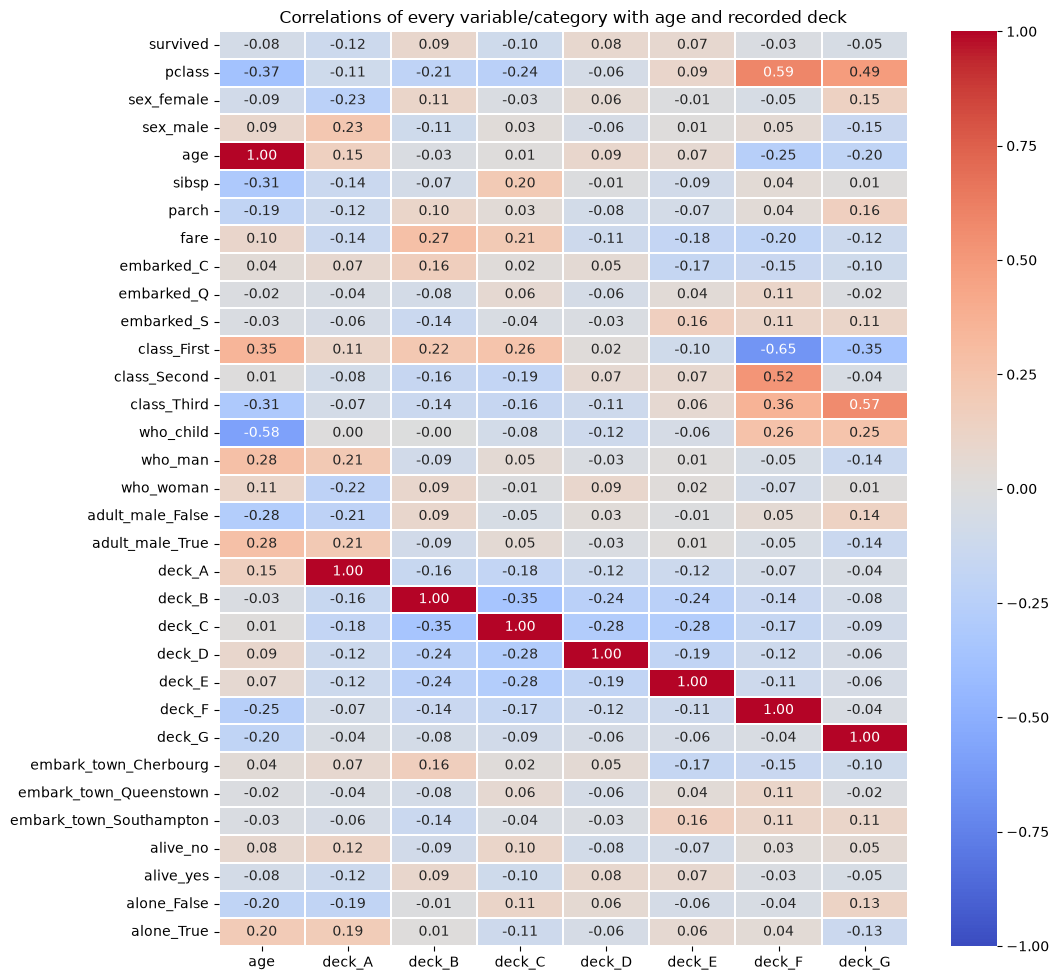

,correlation_with_age
who_child,-0.582875
pclass,-0.369226
class_First,0.348941
class_Third,-0.312271
sibsp,-0.308247
adult_male_False,-0.280328
adult_male_True,0.280328
who_man,0.280328
deck_F,-0.254737
deck_G,-0.200124


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# One-hot encode categories, retaining missingness in each original column.
encoded_parts = []
for column in titanic.columns:
    values = titanic[column]
    if pd.api.types.is_numeric_dtype(values) and not pd.api.types.is_bool_dtype(values):
        encoded_parts.append(values.astype(float).to_frame())
    else:
        indicators = pd.get_dummies(values, prefix=column, dtype=float)
        indicators.loc[values.isna(), :] = np.nan
        encoded_parts.append(indicators)

correlation_data = pd.concat(encoded_parts, axis=1)
correlation_matrix = correlation_data.corr(method='pearson', min_periods=10)
target_columns = ['age'] + [c for c in correlation_data if c.startswith('deck_')]
age_deck_correlations = correlation_matrix.loc[:, target_columns]
display(age_deck_correlations.round(3))

plt.figure(figsize=(11, max(8, len(age_deck_correlations) * 0.30)))
sns.heatmap(age_deck_correlations, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.3)
plt.title('Correlations of every variable/category with age and recorded deck')
plt.tight_layout()
plt.show()

# For age, rank associations by magnitude (excluding its self-correlation).
display(age_deck_correlations['age'].drop('age').sort_values(
    key=lambda values: values.abs(), ascending=False
).rename('correlation_with_age').to_frame())

**Choose models using validation, not the largest correlation.** Compare median/mode baselines with linear/logistic regression, K-nearest neighbors, and random forests. Age is a regression target (lowest mean absolute error wins); deck is a classification target (highest macro F1 wins, weighting each deck equally).

Use passenger attributes `pclass`, `sex`, `sibsp`, `parch`, `fare`, and `embarked`, plus the other target's **original observed** values. Omit redundant `class`, `embark_town`, and `alone`; omit `who` and `adult_male` because they partly derive from age. Exclude `survived`/`alive` so filling passenger attributes does not require knowing survival. Correlations above are descriptive only; they do not select features using validation labels.

Each pipeline learns predictor imputation, scaling, and encoding **inside each training fold**. Only rows with a recorded target can train or validate that target. Age uses five shuffled folds; deck uses four stratified folds because its rarest recorded category has four examples. The winning model is selected from these candidates, not claimed to be the best possible model. These are model-selection CV scores, not an independent final test. Missingness may differ from the observed rows, especially for deck (77% missing), so scores may be optimistic for the actual missing passengers. Filled values are estimates and can reduce variability.

**Additional classification metrics:** Deck ROC AUC uses predicted probabilities, one-versus-rest (OvR) curves, and an unweighted mean across decks. Macro F2 computes F2 separately for each deck and averages equally, emphasizing recall (beta=2 weights recall four times as much as precision in the formula). Report the mean and sample standard deviation across the same four validation folds; model selection still uses macro F1. **Age ROC AUC and F2 are not applicable** to continuous age regression; use MAE, RMSE, and R2 instead. Turning age into categories would define a different prediction task.

In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

base_features = ['pclass', 'sex', 'sibsp', 'parch', 'fare', 'embarked']
model_source = titanic.copy(deep=True)
# Plain object columns avoid categorical assignment/imputation surprises.
for column in ['sex', 'embarked', 'deck']:
    model_source[column] = model_source[column].astype(object)


def make_preprocessor(features):
    numeric = [c for c in features if pd.api.types.is_numeric_dtype(model_source[c])]
    categorical = [c for c in features if c not in numeric]
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('fill', SimpleImputer(strategy='median', add_indicator=True)),
            ('scale', StandardScaler()),
        ]), numeric),
        ('categorical', Pipeline([
            ('fill', SimpleImputer(strategy='constant', fill_value='Unknown')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical),
    ])


candidates = {
    'age': {
        'Median baseline': DummyRegressor(strategy='median'),
        'Ridge regression': Ridge(alpha=10),
        'KNN regression': KNeighborsRegressor(n_neighbors=15, weights='distance'),
        'Random forest regression': RandomForestRegressor(
            n_estimators=250, min_samples_leaf=3, random_state=42, n_jobs=1),
    },
    'deck': {
        'Mode baseline': DummyClassifier(strategy='most_frequent'),
        'Logistic regression': LogisticRegression(
            max_iter=2000, class_weight='balanced'),
        'KNN classification': KNeighborsClassifier(n_neighbors=7, weights='distance'),
        'Random forest classification': RandomForestClassifier(
            n_estimators=250, min_samples_leaf=2, class_weight='balanced',
            random_state=42, n_jobs=1),
    },
}

validation_tables = {}
best_models = {}
best_model_names = {}
for target in ['age', 'deck']:
    features = base_features + (['deck'] if target == 'age' else ['age'])
    known = model_source[target].notna()
    X_known = model_source.loc[known, features]
    y_known = model_source.loc[known, target]
    if target == 'age':
        cv = KFold(n_splits=5, shuffle=True, random_state=42)
        scoring = {'mae': 'neg_mean_absolute_error',
                   'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}
    else:
        cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
        scoring = {'macro_f1': 'f1_macro', 'accuracy': 'accuracy',
                   'auc': 'roc_auc_ovr',
                   'macro_f2': make_scorer(fbeta_score, beta=2,
                                          average='macro', zero_division=0)}

    rows, pipelines = [], {}
    for name, estimator in candidates[target].items():
        pipeline = Pipeline([('prepare', make_preprocessor(features)),
                             ('model', clone(estimator))])
        scores = cross_validate(pipeline, X_known, y_known, cv=cv,
                                scoring=scoring, error_score='raise')
        if target == 'age':
            row = {'model': name, 'MAE (years)': -scores['test_mae'].mean(),
                   'MAE fold SD': scores['test_mae'].std(ddof=1),
                   'RMSE (years)': -scores['test_rmse'].mean(),
                   'R2': scores['test_r2'].mean()}
        else:
            row = {'model': name, 'Macro F1': scores['test_macro_f1'].mean(),
                   'F1 fold SD': scores['test_macro_f1'].std(ddof=1),
                   'Accuracy': scores['test_accuracy'].mean(),
                   'ROC AUC (macro OvR)': scores['test_auc'].mean(),
                   'AUC fold SD': scores['test_auc'].std(ddof=1),
                   'Macro F2': scores['test_macro_f2'].mean(),
                   'F2 fold SD': scores['test_macro_f2'].std(ddof=1)}
        rows.append(row)
        pipelines[name] = pipeline

    table = pd.DataFrame(rows).set_index('model')
    table = table.sort_values('MAE (years)' if target == 'age' else 'Macro F1',
                              ascending=(target == 'age'))
    validation_tables[target] = table
    winner = table.index[0]
    best_model_names[target] = winner
    best_models[target] = pipelines[winner].fit(X_known, y_known)
    print(f'{target}: selected {winner} from the tested candidates')
    display(table.round(3))

In [18]:
# Predict only originally missing values, preserving all recorded ages/decks.
# Both models use original predictors, so predicted age is not fed into deck.
titanic_model_imputed = titanic.copy(deep=True)
imputed_passengers = {}
for target in ['age', 'deck']:
    missing = titanic[target].isna()
    features = base_features + (['deck'] if target == 'age' else ['age'])
    predictions = best_models[target].predict(model_source.loc[missing, features])
    titanic_model_imputed.loc[missing, target] = predictions
    titanic_model_imputed[f'{target}_was_missing'] = missing
    imputed_passengers[target] = titanic_model_imputed.loc[
        missing, base_features + ['age', 'deck', f'{target}_was_missing']
    ].copy()
    print(f'{target}: filled {missing.sum()} rows using {best_model_names[target]}')
    display(imputed_passengers[target])

# Deck probabilities show model uncertainty, not calibrated confidence.
deck_missing = titanic['deck'].isna()
deck_probabilities = pd.DataFrame(
    best_models['deck'].predict_proba(model_source.loc[deck_missing, base_features + ['age']]),
    index=titanic.index[deck_missing],
    columns=best_models['deck'].named_steps['model'].classes_,
)
deck_probabilities.index.name = 'passenger_index'
print('Estimated class probabilities for passengers with missing deck:')
display(deck_probabilities)

missing_comparison = pd.DataFrame({
    'original_missing': titanic[['age', 'deck']].isna().sum(),
    'after_model_imputation': titanic_model_imputed[['age', 'deck']].isna().sum(),
})
display(missing_comparison)
display(pd.DataFrame({'original_age': titanic['age'].describe(),
                      'model_imputed_age': titanic_model_imputed['age'].describe()}))
display(pd.DataFrame({'recorded_decks': titanic['deck'].value_counts(),
                      'predicted_decks': titanic_model_imputed.loc[deck_missing, 'deck'].value_counts()}))
# Missing embarked/embark_town values remain a separate cleaning decision.

age: filled 177 rows using Random forest regression


,pclass,sex,sibsp,parch,fare,embarked,age,deck,age_was_missing
5,3,male,0,0,8.4583,Q,32.093255,NaN,True
17,2,male,0,0,13.0000,S,31.986784,NaN,True
19,3,female,0,0,7.2250,C,17.688773,NaN,True
26,3,male,0,0,7.2250,C,30.702005,NaN,True
28,3,female,0,0,7.8792,Q,20.726822,NaN,True
...,...,...,...,...,...,...,...,...,...
859,3,male,0,0,7.2292,C,25.609735,NaN,True
863,3,female,8,2,69.5500,S,11.765253,NaN,True
868,3,male,0,0,9.5000,S,26.253017,NaN,True
878,3,male,0,0,7.8958,S,27.404794,NaN,True


deck: filled 688 rows using Random forest classification


,pclass,sex,sibsp,parch,fare,embarked,age,deck,deck_was_missing
0,3,male,1,0,7.2500,S,22.000000,F,True
2,3,female,0,0,7.9250,S,26.000000,F,True
4,3,male,0,0,8.0500,S,35.000000,F,True
5,3,male,0,0,8.4583,Q,32.093255,F,True
7,3,male,3,1,21.0750,S,2.000000,F,True
...,...,...,...,...,...,...,...,...,...
884,3,male,0,0,7.0500,S,25.000000,F,True
885,3,female,0,5,29.1250,Q,39.000000,F,True
886,2,male,0,0,13.0000,S,27.000000,F,True
888,3,female,1,2,23.4500,S,19.477287,G,True


Estimated class probabilities for passengers with missing deck:


,A,B,C,D,E,F,G
passenger_index,,,,,,,
0,0.012173,0.015751,0.015083,0.042089,0.068296,0.795525,0.051084
2,0.000471,0.008466,0.000975,0.019599,0.135524,0.487180,0.347785
4,0.022093,0.011677,0.005946,0.110622,0.208962,0.616481,0.024220
5,0.066893,0.022098,0.027418,0.084038,0.140665,0.638001,0.020887
7,0.011298,0.003002,0.005154,0.004748,0.060739,0.656480,0.258578
...,...,...,...,...,...,...,...
884,0.008468,0.005786,0.003573,0.023209,0.066237,0.872156,0.020570
885,0.006818,0.109553,0.068687,0.091129,0.132629,0.336398,0.254786
886,0.057712,0.011377,0.016372,0.209535,0.163911,0.532891,0.008202


,original_missing,after_model_imputation
age,177,0
deck,688,0


,original_age,model_imputed_age
count,714.000000,891.000000
mean,29.699118,29.598840
std,14.526497,13.603437
min,0.420000,0.420000
25%,20.125000,21.000000
50%,28.000000,28.500000
75%,38.000000,37.000000
max,80.000000,80.000000


,recorded_decks,predicted_decks
deck,,
A,15,14
B,47,8
C,59,10
D,33,2
E,32,7
F,13,589
G,4,58


**Result on this dataset (seed 42):** Random forest wins among the tested candidates for both targets. Age cross-validation MAE is **9.81 years**, versus **11.29 years** for median filling. Deck macro F1 is **0.451**, accuracy is **39.9%**, macro one-versus-rest ROC AUC is **0.772 ± 0.026**, and macro F2 is **0.490 ± 0.048** (mean ± sample standard deviation across four folds); this is too weak to treat predicted decks as established facts. Small differences between candidate scores may reflect fold variation.

The models fill 177 ages and 688 decks while preserving recorded values. Of the 688 missing decks, 589 are predicted as F. This large distribution shift is a warning about extrapolating from the small, nonrepresentative recorded-deck subset. Keep the missingness flags and compare conclusions against leaving deck unknown or dropping it. These predictions are an experiment, not recovered historical records.

## Step 7: Run Descriptive Statistics Again

In [19]:
# Descriptive statistics of numerical columns
titanic_cleaned.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [20]:
# Descriptive statistics of categorial columns
titanic_cleaned.select_dtypes(include=['object', 'category', 'bool']).describe()

/var/folders/x1/q5ftwsxd63l56l4dr27_lk2r0000gn/T/ipykernel_7419/923239583.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  titanic_cleaned.select_dtypes(include=['object', 'category', 'bool']).describe()


,sex,class,who,adult_male,alive,alone
count,891,891,891,891,891,891
unique,2,3,3,2,2,2
top,male,Third,man,True,no,True
freq,577,491,537,537,549,537


## Step 8: Compare Original vs Cleaned Statistics
- Discuss differences in mean, median, and distributions.
- Record your observations.

- `age`: Filling 177 missing entries with median increased the count from 714 to 891. The mean decreased slightly from 29.70 to 29.36, while the median stayed at 28 (as it supposed to). The standard deviation fell from 14.53 to 13.02. The first quartile increased from 20.125 to 22, and the third quartile decreased from 38 to 35. Adding many median values of 28 made the distribution more concentrated around the median, although the minimum and maximum value remain the same.
  
- `embarked`: Filling the two missing values with `Unknown` increased the count from 889 to 891 and the number of categories from 3 to 4. The most common value stayed `S`, with 644 passengers. `Unknown` marks missing information; it is not an actual boarding port.

- `deck`: The column got dropped, removing the 688 missing entries, but also discarded 203 known deck values.

- No rows were dropped, all 891 passengers were kept. Statistics for the other columns remain unchanged.

- `embark_town` still has two missing values, unlike the strategy we discussed in **step 5**, **step 6**'s code didn't drop it, so the cleaned dataset is not completely free of missing data. 

## Step 9: Conclude
- Reflect on whether your chosen methods were suitable.
- Would another approach have been better?

The current methods is quite simple, maybe good way to start, but I think it can be improved further. Median filling kept every passenger and barely changed the mean age, but reduced the spread and created an artificial concentration at age 28. Since age missingness is associated with survival and passenger class, using one median for everyone ignores those differences. Using a regression or KNN method, though more complex, might gives better approximation of the missing age entries. 

Using `Unknown` for `embarked` makes the missing information explicit without guessing a port, but it does not recover the actual values. I'd just drop that 0.22% missing rows instead. 

Dropping `deck` is understandable with about 77% missing, although it loses the known values and potentially useful information related to class and survival. Keeping an `Unknown` deck category could preserve that information without guessing decks. Also, patterns in `pclass` and `fare` might be useable for predicting `deck` category, but I'd test it extensively first; the large amount of missing deck data makes reliable prediction difficult.

`embark_town` is left unchanged, maybe the original 'data scientist' intended to use `embarke


## Step 10: Ask Generative AI for Suggestions
- Example prompt: *"Suggest better ways to handle missing data in the Titanic dataset."*
- Record the AI’s suggestions and evaluate them.
- Compare these AI's suggestions to the previous AI's.
- Note how effective the AI was in helping you overall.

**Prompt:**
> *** point codex to this local working directory ***
> 
> read `missing_titanic.ipynb`, then suggest improvements to my Titanic missing-data cleaning: median-fill `age` (19.87% missing), fill `embarked` with `Unknown` (0.22%), and drop `deck` (77.22%). `embark_town` still has two missing values. Give practical alternatives and explain their limitations.

**AI's suggestions:**
> - `age`: Try median age within groups defined by passenger class and sex, with the overall median as a fallback. KNN or regression are alternatives, but require suitable predictors and validation. None guarantees recovery of the true ages.
>
> - `embarked` and `embark_town`: Handle them consistently because they represent the same information. Keep an unknown category in both, or drop both if boarding location is unnecessary for the analysis.
>
> - `deck`: Consider retaining the recorded decks and adding an `Unknown` category. With so much missing data, predicting decks from class and fare needs strong evidence and careful validation.
>
> - Evaluate age-imputation methods by temporarily hiding some known ages and comparing estimates with the actual values. Also compare distributions before and after cleaning. This is useful, but may not reflect performance on the truly missing ages because their missingness may follow a different pattern.
>

**Comparison to previous AI's & note on effectiveness of AI:**
They're essentially the same, GPT-6-Astra via codex. I don't think we can compare the performance of the model with this short of a task either. But, as this task is quite easy, my experience going through this assignment is quite smooth. The llm suggestion is very helpful.

---